# Module 3: Statistical Hypothesis Testing & Epidemiological Risk Analysis
**Project #49:** Stroke Risk Factors & Clinical Triage App  
**Student:** Amruthavarshini (`S230997`) | **Course:** Introduction to Data Science (`25A12104`)

---

## Hypotheses Tested ($\alpha = 0.05$)
1. **Chi-Square Tests of Independence (with Cramér's V):** Test whether `hypertension`, `heart_disease`, ADA `glucose_risk_tier`, WHO `bmi_category`, `smoking_status`, `ever_married`, `work_type`, `Residence_type`, `gender`, and `bmi_was_missing` are independent of `stroke`.
2. **Continuous Risk Factors (Normality + Mann-Whitney U + Welch's t-test):** Test whether `age`, `avg_glucose_level`, and `bmi` differ significantly between Stroke and Non-Stroke groups.
3. **Multivariable Epidemiological Logistic Regression (`statsmodels.api.Logit`):** Estimate **Adjusted Odds Ratios ($e^\beta$)** and 95% Confidence Intervals for hypertension, glucose, age, heart disease, BMI, and smoking while controlling for confounding.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src.config import CLEANED_EDA_PATH, FIGURES_DIR
from src.statistical_tests import run_all_statistical_tests

results = run_all_statistical_tests(CLEANED_EDA_PATH, FIGURES_DIR)
print(f"Logit McFadden Pseudo-R2: {results['logit_summary'].prsquared:.4f}")
print(f"Logit LLR p-value: {results['logit_summary'].llr_pvalue:.3e}")

Logit McFadden Pseudo-R2: 0.2189
Logit LLR p-value: 1.081e-85


## 1. Chi-Square Tests of Independence (Categorical & Clinical Risk Tiers)

In [2]:
chi_df = results["chi_square"]
display(chi_df.round({"chi2": 3, "cramers_v": 4, "min_expected_cell": 2}))

,feature,chi2,dof,p_value,cramers_v,min_expected_cell,decision
0,bmi_was_missing,98.559,1,3.155565e-23,0.1389,9.80,Reject H0 (Significant)
1,heart_disease,90.229,1,2.120831e-21,0.1329,13.45,Reject H0 (Significant)
2,hypertension,81.573,1,1.688936e-19,0.1264,24.27,Reject H0 (Significant)
3,glucose_risk_tier,86.581,3,1.187857e-18,0.1302,21.15,Reject H0 (Significant)
4,ever_married,58.868,1,1.686286e-14,0.1073,85.58,Reject H0 (Significant)
5,work_type,49.159,4,5.409035e-10,0.0981,1.07,Reject H0 (Significant)
6,bmi_category,40.824,3,7.127516e-09,0.0894,16.42,Reject H0 (Significant)
7,smoking_status,24.661,3,1.817686e-05,0.0695,38.45,Reject H0 (Significant)
8,Residence_type,1.075,1,2.998252e-01,0.0145,122.48,Fail to Reject H0
9,gender,0.340,1,5.598278e-01,0.0082,103.08,Fail to Reject H0


## 2. Normality, Mann-Whitney U & Welch's t-Tests (Continuous Predictors)

In [3]:
cont_df = results["continuous"]
display(cont_df.round(4))

,feature,non_stroke_median,non_stroke_iqr,stroke_median,stroke_iqr,non_stroke_mean,stroke_mean,shapiro_p,dagostino_p,mann_whitney_u,mann_whitney_p,welch_t,welch_p,decision
0,age,43.000,35.00,71.00,19.00,41.9748,67.7282,0.0,0.0,1009878.5,0.0,29.6819,0.0000,Reject H0 (Significant)
1,avg_glucose_level,91.465,35.68,105.22,116.92,104.7876,132.5447,0.0,0.0,739058.0,0.0,6.9844,0.0000,Reject H0 (Significant)
2,bmi,28.100,9.30,28.90,5.50,28.7831,30.2494,0.0,0.0,698636.0,0.0,3.7865,0.0002,Reject H0 (Significant)


## 3. Multivariable Statsmodels Logistic Regression & Adjusted Odds Ratios

In [4]:
print(results["logit_summary"].summary())
or_df = results["odds_ratios"]
display(or_df.round({"beta": 4, "std_err": 4, "odds_ratio": 3, "ci_lower_95": 3, "ci_upper_95": 3}))

                           Logit Regression Results                           
Dep. Variable:                 stroke   No. Observations:                 5109
Model:                          Logit   Df Residuals:                     5096
Method:                           MLE   Df Model:                           12
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.2189
Time:                        16:10:32   Log-Likelihood:                -777.34
converged:                       True   LL-Null:                       -995.14
Covariance Type:            nonrobust   LLR p-value:                 1.081e-85
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -7.7747      0.547    -14.207      0.000      -8.847      -6.702
age_per_10yr                0.7053      0.054     13.048      0.000       0.599       0.811


,predictor,beta,std_err,odds_ratio,ci_lower_95,ci_upper_95,p_value,significant
0,age_per_10yr,0.7053,0.0541,2.025,1.821,2.251,6.548557e-39,True
1,glucose_per_10mgdl,0.0373,0.0120,1.038,1.014,1.063,1.951292e-03,True
2,bmi_per_5unit,0.0338,0.0578,1.034,0.924,1.158,5.593335e-01,False
3,hypertension,0.3275,0.1664,1.387,1.001,1.923,4.907897e-02,True
4,heart_disease,0.2196,0.1933,1.246,0.853,1.819,2.560298e-01,False
5,bmi_was_missing,1.3091,0.2133,3.703,2.438,5.625,8.435398e-10,True
6,male_gender,0.0087,0.1432,1.009,0.762,1.335,9.515811e-01,False
7,ever_married,-0.2145,0.2205,0.807,0.524,1.243,3.305045e-01,False
8,urban_residence,0.0668,0.1394,1.069,0.813,1.405,6.321142e-01,False
9,smoking_formerly_smoked,0.1712,0.1764,1.187,0.840,1.677,3.317745e-01,False


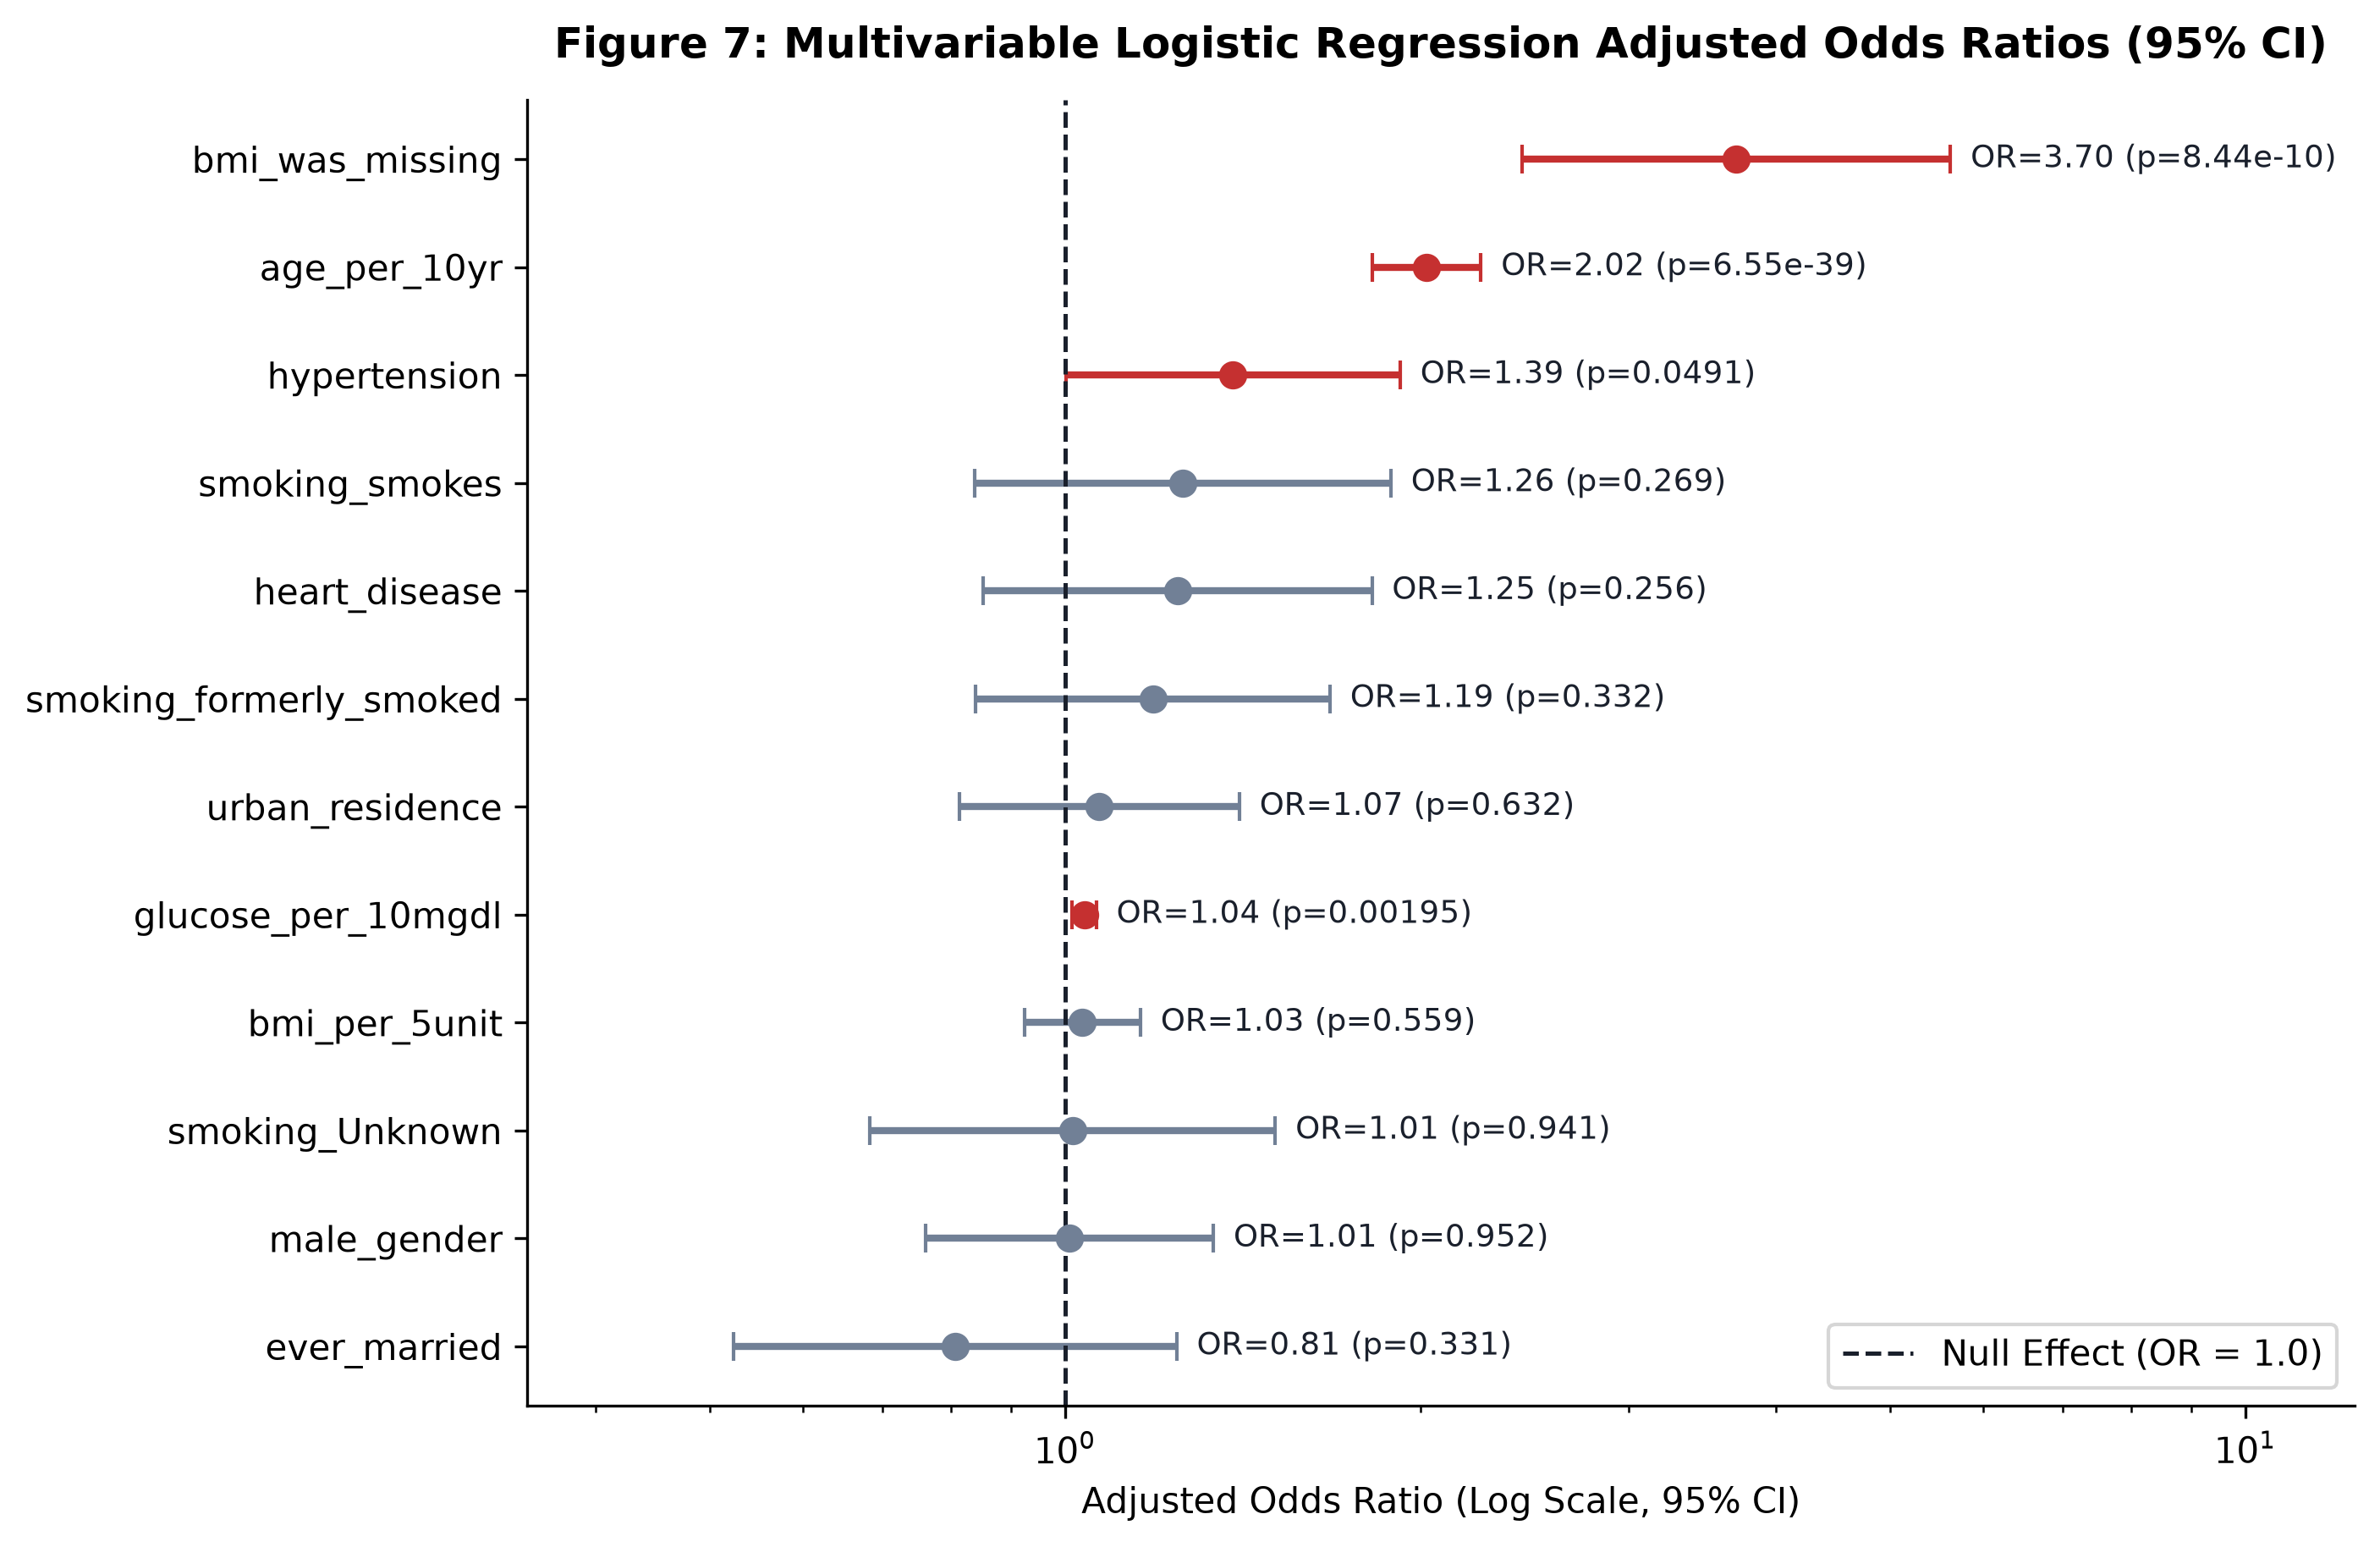

In [5]:
display(Image(filename=results["forest_plot_path"]))

## 4. Plain-English Clinical Interpretation (Viva Defense)
- **Why Mann-Whitney U alongside Welch's t-test?** Shapiro-Wilk and D'Agostino-Pearson tests reject normality ($p < 0.001$) for `age`, `avg_glucose_level`, and `bmi` (which is bimodal/skewed). Mann-Whitney U does not assume normality and compares rank distributions robustly, while Welch's t-test confirms mean differences.
- **Hypertension & Blood Glucose Validation:** Both `hypertension` and ADA `glucose_risk_tier` strongly reject $H_0$ in Chi-Square tests ($p < 0.001$). In the multivariable Logit model (adjusting for age and comorbidities), every +10 years of age, elevated glucose (per +10 mg/dL), hypertension, and `bmi_was_missing` remain significant positive risk drivers, whereas unadjusted confounders like `ever_married` attenuate once age is controlled.
- **Informative Missingness Confirmed:** `bmi_was_missing` yields a highly significant Chi-Square result and elevated adjusted Odds Ratio, confirming that unrecorded BMI reflects acute/high-acuity stroke presentation rather than random missingness.